In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

In [36]:
df = pd.read_csv(r"C:\Users\hp\Downloads\uber.csv")

print("Dataset Loaded Successfully")

df.head()

Dataset Loaded Successfully


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [37]:
# Display first five rows
print(df.head())

# Display dataset information
print("\nDataset Information:")
df.info()

# Display number of rows and columns
print("\nDataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
print(df.describe())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [38]:
# Remove unnecessary columns
df = df.drop(['Unnamed: 0', 'key'], axis=1, errors='ignore')

# Remove missing values
df = df.dropna()

# Convert pickup_datetime into datetime format
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], errors='coerce', utc=True
)

# Remove invalid datetime rows
df = df.dropna(subset=['pickup_datetime'])

# Remove invalid fare amounts
df = df[df['fare_amount'] > 0]

# Remove invalid passenger counts
df = df[df['passenger_count'].between(1, 6)]

# Remove invalid geographical coordinates
df = df[
    df['pickup_longitude'].between(-180, 180) &
    df['dropoff_longitude'].between(-180, 180) &
    df['pickup_latitude'].between(-90, 90) &
    df['dropoff_latitude'].between(-90, 90)
]

# Remove zero coordinates
df = df[
    (df['pickup_longitude'] != 0) &
    (df['pickup_latitude'] != 0) &
    (df['dropoff_longitude'] != 0) &
    (df['dropoff_latitude'] != 0)
].copy()

print("Data Preprocessing Completed")
print("Dataset Shape:", df.shape)

df.head()

Data Preprocessing Completed
Dataset Shape: (195313, 7)


,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5


In [39]:
# Extract date and time features
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['weekday'] = df['pickup_datetime'].dt.dayofweek

# Calculate distance using Haversine formula
def calculate_distance(lat1, lon1, lat2, lon2):

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2

    c = 2 * np.arcsin(np.sqrt(a))

    return 6371 * c

df['distance'] = calculate_distance(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

print("Feature Extraction Completed")

df[['distance', 'hour', 'day', 'month', 'weekday']].head()

Feature Extraction Completed


,distance,hour,day,month,weekday
0,1.683323,19,7,5,3
1,2.457590,20,17,7,4
2,5.036377,21,24,8,0
3,1.661683,8,26,6,4
4,4.475450,17,28,8,3


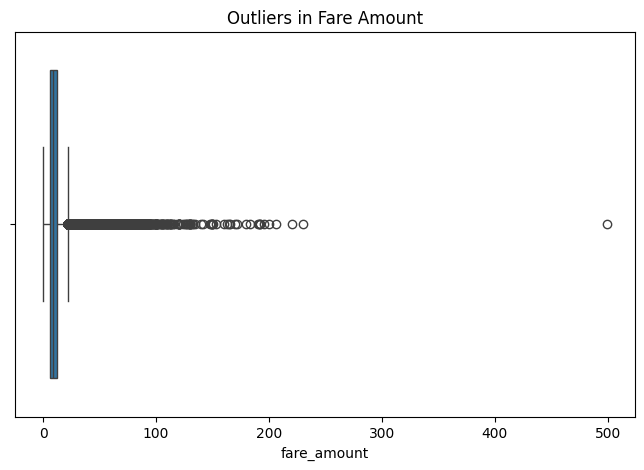

Lower Limit: -3.75
Upper Limit: 22.25
Number of Outliers: 16740


In [40]:
# Display boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['fare_amount'])
plt.title("Outliers in Fare Amount")
plt.show()

# Calculate IQR
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

# Count outliers
outliers = df[
    (df['fare_amount'] < lower_limit) |
    (df['fare_amount'] > upper_limit)
]

print("Number of Outliers:", len(outliers))

In [41]:
# Remove fare amount outliers
df = df[
    (df['fare_amount'] >= lower_limit) &
    (df['fare_amount'] <= upper_limit)
].copy()

# Remove zero-distance trips
df = df[df['distance'] > 0].copy()

print("Outliers Removed Successfully")
print("Remaining Dataset Shape:", df.shape)

Outliers Removed Successfully
Remaining Dataset Shape: (176722, 12)


                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.000512        -0.001956   
pickup_longitude      0.000512          1.000000        -0.964080   
pickup_latitude      -0.001956         -0.964080         1.000000   
dropoff_longitude     0.001479          0.943480        -0.963466   
dropoff_latitude     -0.002266         -0.959730         0.992190   
passenger_count       0.013065          0.009628        -0.009880   
hour                 -0.013132          0.002261        -0.002370   
day                   0.006555          0.017921        -0.018799   
month                 0.026633         -0.007664         0.007620   
weekday               0.020390          0.007019        -0.007122   
distance              0.015303          0.153968        -0.023680   

                   dropoff_longitude  dropoff_latitude  passenger_count  \
fare_amount                 0.001479         -0.002266         0.013065   
pickup_longitude     

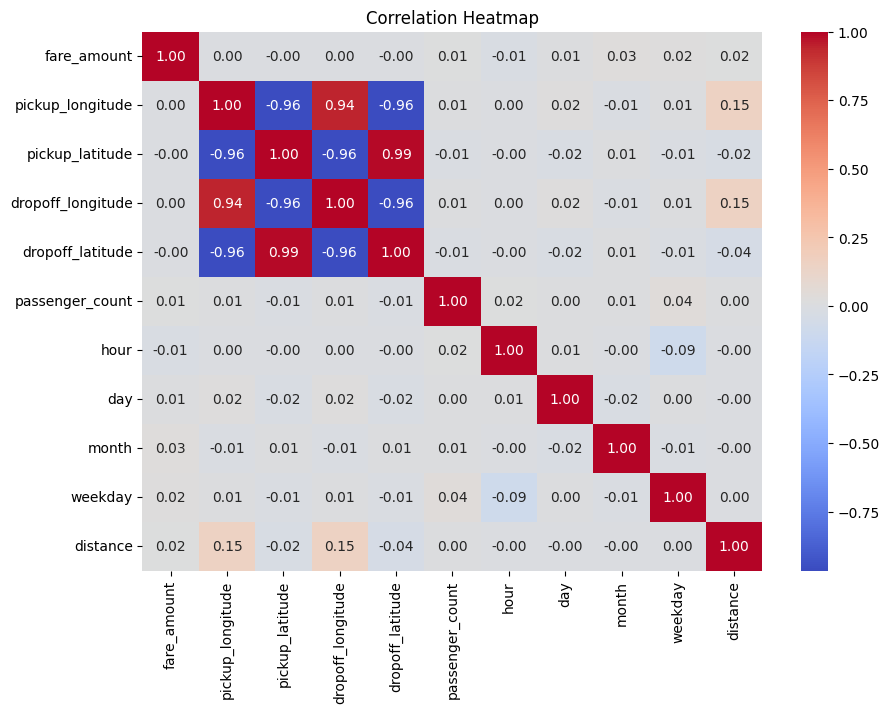

In [42]:
# Select numerical columns
correlation = df.select_dtypes(include=np.number).corr()

# Display correlation
print(correlation)

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

In [43]:
# Select input features
X = df[
    [
        'pickup_longitude',
        'pickup_latitude',
        'dropoff_longitude',
        'dropoff_latitude',
        'passenger_count',
        'hour',
        'day',
        'month',
        'weekday',
        'distance'
    ]
]

# Select target variable
y = df['fare_amount']

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (141377, 10)
Testing Data: (35345, 10)


In [44]:
# Create Linear Regression model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

# Predict fare
lr_pred = lr_model.predict(X_test)

print("Linear Regression Model Trained Successfully")

Linear Regression Model Trained Successfully


In [45]:
# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Predict fare
rf_pred = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully")

Random Forest Model Trained Successfully


In [46]:
# Linear Regression Evaluation
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_mse = mean_squared_error(y_test, lr_pred)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, lr_pred)

# Random Forest Evaluation
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Linear Regression Results")
print("MAE:", lr_mae)
print("MSE:", lr_mse)
print("RMSE:", lr_rmse)
print("R2 Score:", lr_r2)

print("\nRandom Forest Results")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Linear Regression Results
MAE: 3.2826356967188963
MSE: 17.10774654562419
RMSE: 4.136151175383244
R2 Score: 0.0021264505436675574

Random Forest Results
MAE: 1.480066057433866
MSE: 4.380719791511105
RMSE: 2.093016911425014
R2 Score: 0.7444780704535919


In [47]:
# Create comparison table
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [lr_mae, rf_mae],
    'MSE': [lr_mse, rf_mse],
    'RMSE': [lr_rmse, rf_rmse],
    'R2 Score': [lr_r2, rf_r2]
})

print(results)

               Model       MAE        MSE      RMSE  R2 Score
0  Linear Regression  3.282636  17.107747  4.136151  0.002126
1      Random Forest  1.480066   4.380720  2.093017  0.744478


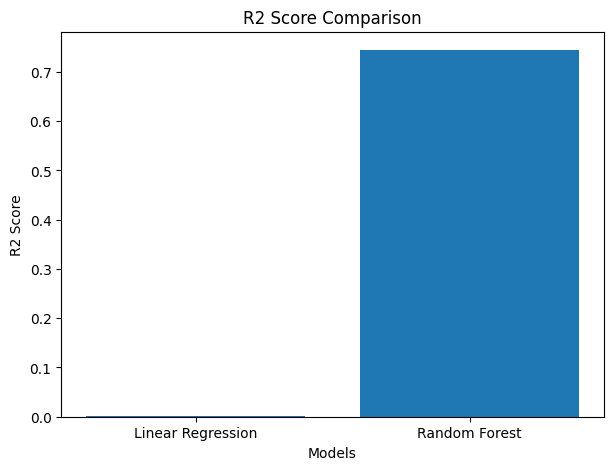

In [48]:
# Compare R2 scores
plt.figure(figsize=(7, 5))

plt.bar(
    results['Model'],
    results['R2 Score']
)

plt.title("R2 Score Comparison")
plt.ylabel("R2 Score")
plt.xlabel("Models")
plt.show()

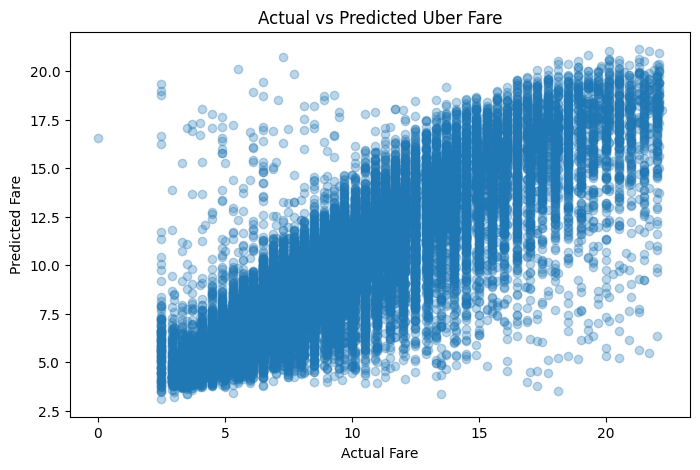

In [49]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_pred, alpha=0.3)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")

plt.title("Actual vs Predicted Uber Fare")

plt.show()

In [50]:
# Example new ride details

new_ride = pd.DataFrame([{
    'pickup_longitude': -73.985,
    'pickup_latitude': 40.748,
    'dropoff_longitude': -73.985,
    'dropoff_latitude': 40.758,
    'passenger_count': 2,
    'hour': 10,
    'day': 15,
    'month': 5,
    'weekday': 2,
    'distance': 1.11
}])

# Predict using Random Forest
predicted_fare = rf_model.predict(new_ride)

print("Predicted Uber Fare: $", round(predicted_fare[0], 2))

Predicted Uber Fare: $ 6.42


First 5 Records:
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647             

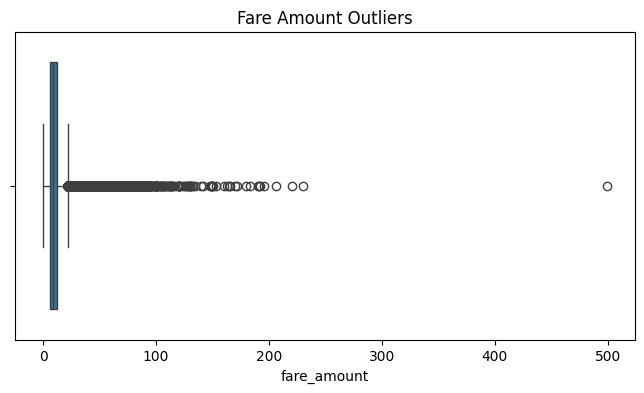


Lower Bound: -3.75
Upper Bound: 22.25
Number of Outliers: 16540

Correlation Matrix:
                 fare_amount  distance  passenger_count      hour       day  \
fare_amount         1.000000  0.723498         0.013017 -0.013121  0.006575   
distance            0.723498  1.000000         0.000195 -0.032688  0.006123   
passenger_count     0.013017  0.000195         1.000000  0.015268  0.002853   
hour               -0.013121 -0.032688         0.015268  1.000000  0.005660   
day                 0.006575  0.006123         0.002853  0.005660  1.000000   
month               0.026705  0.005301         0.008511 -0.003065 -0.016307   
weekday             0.020356  0.034328         0.037659 -0.088033  0.004745   

                    month   weekday  
fare_amount      0.026705  0.020356  
distance         0.005301  0.034328  
passenger_count  0.008511  0.037659  
hour            -0.003065 -0.088033  
day             -0.016307  0.004745  
month            1.000000 -0.009565  
weekday        

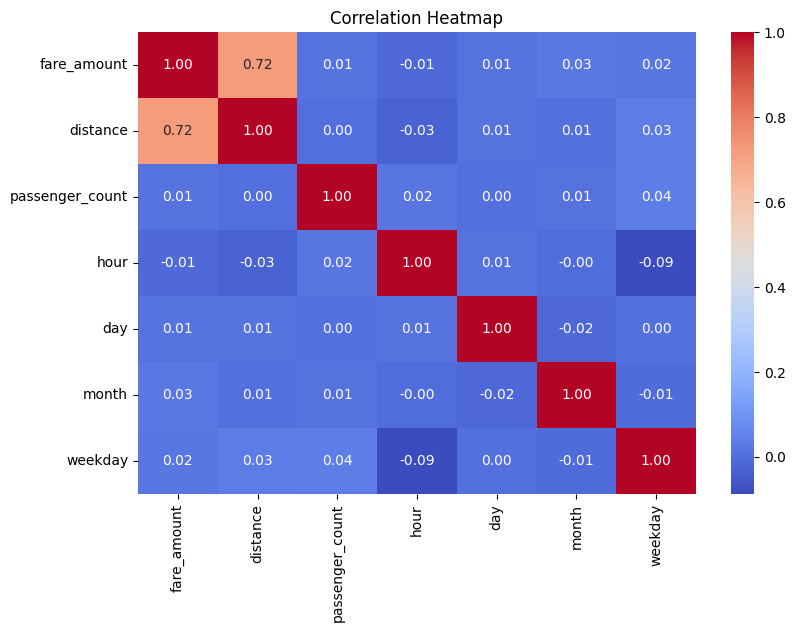


Training Data: (141320, 6)
Testing Data: (35331, 6)

 Linear Regression
R2 Score: 0.5838
RMSE: 2.6635
MAE: 1.8888

 Random Forest Regression
R2 Score: 0.6886
RMSE: 2.3038
MAE: 1.6645

Model Comparison:
                   R2 Score      RMSE      MAE
Linear Regression  0.583774  2.663472  1.88885
Random Forest      0.688599  2.303795  1.66454


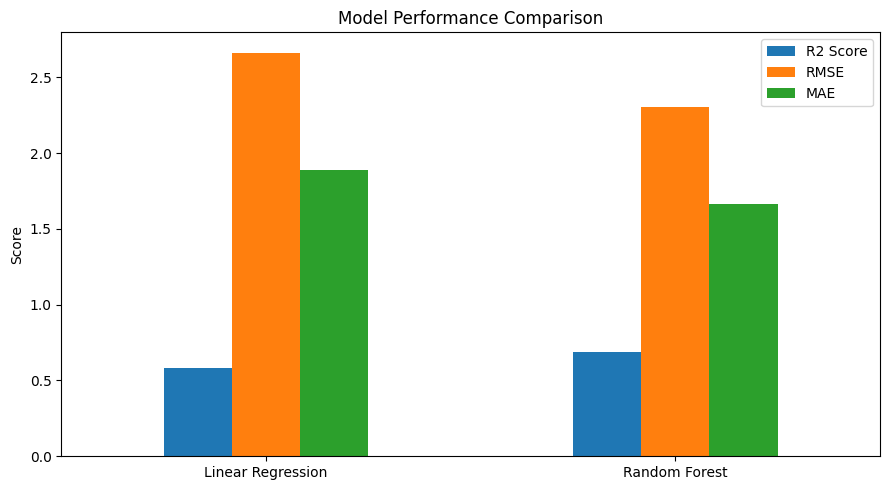


Predicted Uber Fare:
Fare Amount: $ 15.74


In [51]:

# Uber Fare Price Prediction using Machine Learning

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


# 2. Load Dataset
df = pd.read_csv(r"C:\Users\hp\Downloads\uber.csv")

print("First 5 Records:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())


# 3. Data Preprocessing

# Remove missing values and duplicates
df = df.dropna()
df = df.drop_duplicates()

# Convert pickup_datetime into datetime format
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], errors='coerce'
)

df = df.dropna(subset=['pickup_datetime'])

# Remove invalid fare and passenger values
df = df[df['fare_amount'] > 0]
df = df[df['passenger_count'].between(1, 6)]

# Remove invalid geographical coordinates
df = df[
    df['pickup_latitude'].between(-90, 90) &
    df['dropoff_latitude'].between(-90, 90) &
    df['pickup_longitude'].between(-180, 180) &
    df['dropoff_longitude'].between(-180, 180)
]

# Remove zero coordinates
df = df[
    (df['pickup_latitude'] != 0) &
    (df['dropoff_latitude'] != 0) &
    (df['pickup_longitude'] != 0) &
    (df['dropoff_longitude'] != 0)
]

print("\nAfter Preprocessing:")
print(df.shape)


# 4. Calculate Distance using Haversine Formula

def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Earth radius in km

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2)**2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon / 2)**2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c


df['distance'] = haversine(
    df['pickup_latitude'],
    df['pickup_longitude'],
    df['dropoff_latitude'],
    df['dropoff_longitude']
)

# Remove zero and unusually large distances
df = df[
    (df['distance'] > 0) &
    (df['distance'] < 100)
]


# 5. Extract Date and Time Features

df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['weekday'] = df['pickup_datetime'].dt.weekday

print("\nNew Features:")
print(df[['distance', 'hour', 'day', 'month', 'weekday']].head())


# 6. Identify Outliers using IQR

plt.figure(figsize=(8, 4))
sns.boxplot(x=df['fare_amount'])
plt.title("Fare Amount Outliers")
plt.show()


Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("\nLower Bound:", lower)
print("Upper Bound:", upper)

outliers = df[
    (df['fare_amount'] < lower) |
    (df['fare_amount'] > upper)
]

print("Number of Outliers:", len(outliers))

# Remove fare outliers
df = df[
    (df['fare_amount'] >= lower) &
    (df['fare_amount'] <= upper)
]


# 7. Correlation Analysis

features = [
    'fare_amount', 'distance', 'passenger_count',
    'hour', 'day', 'month', 'weekday'
]

correlation = df[features].corr()

print("\nCorrelation Matrix:")
print(correlation)

plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()


# 8. Select Features and Target

X = df[
    ['distance', 'passenger_count',
     'hour', 'day', 'month', 'weekday']
]

y = df['fare_amount']


# 9. Split Dataset into Training and Testing

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# 10. Linear Regression Model

lr = LinearRegression()

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)


# 11. Random Forest Regression Model

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)


# 12. Model Evaluation

def evaluate_model(name, actual, predicted):

    r2 = r2_score(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mae = mean_absolute_error(actual, predicted)

    print("\n", name)
    print("R2 Score:", round(r2, 4))
    print("RMSE:", round(rmse, 4))
    print("MAE:", round(mae, 4))

    return [r2, rmse, mae]


lr_scores = evaluate_model(
    "Linear Regression", y_test, lr_pred
)

rf_scores = evaluate_model(
    "Random Forest Regression", y_test, rf_pred
)


# 13. Compare Both Models

comparison = pd.DataFrame(
    [lr_scores, rf_scores],
    columns=['R2 Score', 'RMSE', 'MAE'],
    index=['Linear Regression', 'Random Forest']
)

print("\nModel Comparison:")
print(comparison)


# 14. Visualize Model Comparison

comparison.plot(
    kind='bar',
    figsize=(9, 5),
    title='Model Performance Comparison'
)

plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 15. Predict Uber Fare for a New Ride

new_ride = pd.DataFrame([{
    'distance': 5,
    'passenger_count': 2,
    'hour': 10,
    'day': 15,
    'month': 6,
    'weekday': 2
}])

predicted_fare = rf.predict(new_ride)

print("\nPredicted Uber Fare:")
print("Fare Amount: $", round(predicted_fare[0], 2))
